
# 2. Linear Regression Multiple Variables


In [82]:
import pandas as pd
import numpy as np
from sklearn import linear_model
import matplotlib.pyplot as plt

## Initialising data

In [3]:
df = pd.read_csv('hiring.csv')
df

,experience,test_score(out of 10),interview_score(out of 10),salary($)
0,NaN,8.0,9,50000
1,NaN,8.0,6,45000
2,five,6.0,7,60000
3,two,10.0,10,65000
4,seven,9.0,6,70000
5,three,7.0,10,62000
6,ten,NaN,7,72000
7,eleven,7.0,8,80000


## Preprocessing data

In [30]:
from word2num import word2num

# Safe conversion function
def convert_word_to_int(val):
  if isinstance(val, str):
    try:
      return word2num(val)
    except ValueError:
      return val  # return original if it fails to parse
  return val


# Apply across the target column
df['experience'] = df['experience'].apply(convert_word_to_int)

# Save the cleaned CSV
df.to_csv('cleaned_hiring.csv', index=False)



In [77]:
df = df.astype({'experience': 'Int64', 'test_score(out of 10)': 'Int64'})

df = df.fillna({'experience': df['experience'].median(), 'test_score(out of 10)': df['test_score(out of 10)'].median()})

df[['experience','test_score(out of 10)', 'interview_score(out of 10)']]

,experience,test_score(out of 10),interview_score(out of 10)
0,6,8,9
1,6,8,6
2,5,6,7
3,2,10,10
4,7,9,6
5,3,7,10
6,10,8,7
7,11,7,8


## Multi-linear regression training

In [54]:
reg = linear_model.LinearRegression()
reg.fit(df[['experience', 'test_score(out of 10)', 'interview_score(out of 10)']], df['salary($)'])

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [78]:
print(reg.coef_, reg.intercept_)

[2813.00813008 1333.33333333 2926.82926829] 11869.918699186957


## Multi-linear regression results

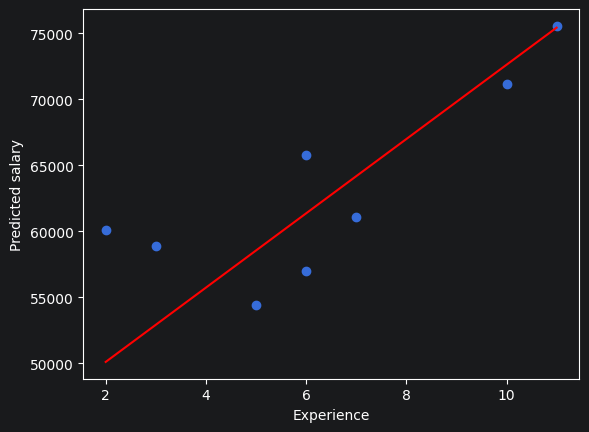

In [101]:
features = ['experience', 'test_score(out of 10)',
            'interview_score(out of 10)']

plt.scatter(df['experience'], reg.predict(df[features]))

experience = np.linspace(df['experience'].min(),
                         df['experience'].max(), 100)

X_plot = pd.DataFrame({
    'experience': experience,
    'test_score(out of 10)': df['test_score(out of 10)'].median(),
    'interview_score(out of 10)': df['interview_score(out of 10)'].median()
})

plt.plot(experience, reg.predict(X_plot[features]), color='red')

plt.xlabel('Experience')
plt.ylabel('Predicted salary')
plt.show()